In [71]:
import pandas as pd
df = pd.read_parquet("../data/detention-stints-latest.parquet")



In [72]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)
pd.set_option('display.max_rows', None)

### CLEAN

remove rows where unique_identifier is null

In [73]:
df = df.sort_values(["unique_identifier","book_in_date_time"]) 

df.isna().sum().sort_values(ascending=False)

#we should remove rows where unique_identifier and/or stay_ID (these always go together) are null 
#because there is no way to track these stints. 

UInulls = df["unique_identifier"].isna()
df = df[df["unique_identifier"].notna()]

add a column for federal appeals circuit based on state 

In [74]:
#"federal_court_circuit_of_confinement" has a ton of nulls, so now must make our own column 

#I did this last semester before DDP added federal_court_circuit_of_confinement column into the data, 
#so copying that dictionary over 

state_to_circuit = {
    # 1st Circuit
    'ME': '1', 'NH': '1', 'MA': '1', 'RI': '1', 'PR': '1',
    # 2nd Circuit
    'NY': '2', 'CT': '2', 'VT': '2',
    # 3rd Circuit
    'PA': '3', 'NJ': '3', 'DE': '3', 'VI': '3',
    # 4th Circuit
    'MD': '4', 'VA': '4', 'WV': '4', 'NC': '4', 'SC': '4',
    # 5th Circuit
    'TX': '5', 'LA': '5', 'MS': '5',
    # 6th Circuit
    'MI': '6', 'OH': '6', 'KY': '6', 'TN': '6',
    # 7th Circuit
    'IL': '7', 'IN': '7', 'WI': '7',
    # 8th Circuit
    'MN': '8', 'IA': '8', 'MO': '8', 'AR': '8',
    'NE': '8', 'ND': '8', 'SD': '8',
    # 9th Circuit
    'CA': '9', 'OR': '9', 'WA': '9', 'AK': '9', 'HI': '9',
    'AZ': '9', 'NV': '9', 'ID': '9', 'MT': '9', 'GU': '9', 'MP': '9',
    # 10th Circuit
    'CO': '10', 'WY': '10', 'UT': '10',
    'KS': '10', 'OK': '10', 'NM': '10',
    # 11th Circuit
    'FL': '11', 'GA': '11', 'AL': '11',
    # DC Circuit
    'DC': 'DC',
}

df["circuit"] = df["state"].map(state_to_circuit)


add columns for geography of each person's first detention 

In [75]:
#I want to add columns that indicate the state and circuit each person was FIRST detained in. 
#I am going to do this with a merge, making a df of location data to merge with main df 

#We could merge on stay_ID or unique_identifier.
#using stay_ID --- later on I will filter out people with multiple stays, but not yet.

#get the index value (for .loc use) of the FIRST stint for each stay 
first_stint_index = df.groupby("stay_ID")["book_in_date_time"].idxmin() 

#make new df called first_location where we can vlookup by those index values, and get location data and stay_ID for each. 
first_location = df.loc[first_stint_index, ["stay_ID", "state", "circuit", "city"]]

#rename the columns so they won't be the same name when merged 
first_location = first_location.rename(columns={"state":"state_first_detained", 
                                          "circuit":"circuit_first_detained",
                                          "city": "city_first_detained"
                                          })
#merge for new df
df1 = pd.merge(
    df,
    first_location,
    on='stay_ID',
    how='left'
)

make a filtered df for just second Trump administration

In [76]:
inauguration = pd.Timestamp("2025-1-20T000:00:00", tz="UTC")

#dataframe of Stints where the detention Stay only began post-inauguration:

dfadmin = df1[df1["stay_book_in_date_time"] >= inauguration]

remove small amt of people whose first state is null 

In [ ]:
#figuring out that some nulls in "state" I found were all for a person's first detention stint 

nullstates = dfadmin[dfadmin["state"].isna()]
print(f"{len(nullstates)} rows where state is null") 
print("--")
print(nullstates["state_first_detained"].value_counts(dropna=False))
print(f"and all of them have state_first_detained as null too (a total overlap; it should be just the first state missing)")
print("--")
print(f"{nullstates["unique_identifier"].nunique()} people in the nullstates set")

#in this analysis cannot include people who have unknown first detention location
#filter out 

nullstates = nullstates.sort_values(["stay_ID", "book_in_date_time"])
#nullstates.head(30)

dfadmin = dfadmin[~dfadmin["unique_identifier"].isin(nullstates["unique_identifier"])]
#dfadmin["state_first_detained"].value_counts(dropna=False)
#worked

370 rows where state is null
--
state_first_detained
NaN    370
Name: count, dtype: int64
and all of them have state_first_detained as null too (a total overlap; it should be just the first state missing)
--
362 people in the nullstates set


remove people that have multiple Stays (not Stints) in detention (or ideally figure out how to work with this and not delete them..)

In [78]:
#check for poeple that have multiple stays 

staysperperson = dfadmin.groupby("unique_identifier")["stay_ID"].nunique()

multistays = staysperperson[staysperperson > 1]

print(multistays.index.nunique()) 

print(dfadmin["unique_identifier"].nunique())

multistayfinal = dfadmin[dfadmin["unique_identifier"].isin(multistays.index)]
#just looking at for those who have multiple stays, how many stays did they tend to have? out of curiosity
print(multistayfinal.groupby("unique_identifier")["stay_ID"].nunique().value_counts())

24273
591385
stay_ID
2    23224
3      989
4       54
5        6
Name: count, dtype: int64


In [64]:
#filter down to only people with one stay for more straightforward analysis
dfadmin1stay = dfadmin[~dfadmin["unique_identifier"].isin(multistayfinal["unique_identifier"])]
dfadmin1stay.unique_identifier.nunique()

566752

In [66]:
#add a column indicating which stint(first, second, etc) this is for a person's Stay.
dfadmin1stay["stint_number"] = dfadmin1stay.groupby("unique_identifier")["book_in_date_time"].rank().astype(int)
#(I did not actually end up using this much but i feel like it could be useful)

In [68]:
#dfadmin1stay["stint_number"].value_counts(dropna=False)

In [14]:
dfadmin1stay.groupby("circuit_first_detained", dropna=False)["unique_identifier"].nunique()
#dfadmin1stay.groupby("state", dropna=False)["unique_identifier"].nunique()


circuit_first_detained
1      12969
10     33403
11    102706
2      25281
3      32068
4      41114
5     155752
6      36922
7      18004
8      25049
9      83484
Name: unique_identifier, dtype: int64

In [15]:
ddf = dfadmin1stay.copy()

make a column for voluntary deportations

In [69]:
#make a column for anything considered a voluntary deportation, which are reported inconsistently and across multiple columns


vd_case_categories = [
    '[1A] Voluntary Departure - Un-Expired and Un-Extended Departure Period',
    '[1B] Voluntary Departure - Extended Departure Period',
    '[5E] Relief Granted - Extended Voluntary Departure',
    '[9] VR Under Safeguards',
    '[8V] Voluntary Departure Granted by IJ'
]

vd_case_statuses = [
    '3-Voluntary Departure Confirmed',
    '9-VR Witnessed',
]

vd_release_reasons = [
    'Voluntary departure',
    'Voluntary Return',
    'Withdrawal'
]

ddf['voluntary_departure'] = (
    ddf["case_category"].isin(vd_case_categories)|
    ddf["case_status"].isin(vd_case_statuses)|
    ddf["stay_release_reason"].isin(vd_release_reasons)
)


In [17]:
ddf["stint_ID"].duplicated().sum()

np.int64(25)

In [18]:
ddf = ddf.drop_duplicates(subset="stint_ID", keep="last")


### ANALYZE

How many still detained?

In [ ]:
#How many still detained?

stillhere = ddf[ddf["stay_release_reason"].isna()]

pplstillhere = stillhere.unique_identifier.nunique()
pplstillhere

62502

of them, how many still detained in 5th circuit?

In [20]:
#How many still detained in 5th circuit?

stillhere = stillhere.sort_values(by=["unique_identifier", "book_in_date_time"])
stillhere.drop_duplicates(subset="unique_identifier",keep='last')

still5 = stillhere[stillhere["circuit"] == '5']

pplin5th = still5.unique_identifier.nunique()

pplin5th

29549

of them, how many with immigration cases never ruled on by a judge?

In [81]:
# How many people currently detained in 5 have cases marked as NOT AT ALL RULED ON by an immigration judge? 
# caseongoing people would rarely EVER be detained in Biden yrs, lawyers have told me, much less in 
# a deportation hub with no right to bond

caseongoing = ["[8B] Excludable / Inadmissible - Under Adjudication by IJ",
                "[8A] Excludable / Inadmissible - Hearing Not Commenced",
                "[2A] Deportable - Under Adjudication by IJ"]

stillhere["case_ongoing"] = stillhere["case_category"].isin(caseongoing)

still5caseongoing = still5[still5["case_ongoing"] == True]
still5caseongoing.unique_identifier.nunique()

pplin5th_withongoingcases = still5caseongoing.unique_identifier.nunique()
pplin5th_withongoingcases

13136

In [82]:

pplin5th_withongoingcases/pplin5th

#nearly half of current detainees in the 5th circuit have open cases, but no right to bond

print(f"{pplstillhere} were in detention at the time of the data's release")
print(f"{pplin5th} people were detained in the fifth circuit, a hub for deportation where detainees are subject to mandatory detention.") 
print(f"{(pplin5th_withongoingcases/pplin5th)*100}% have cases that have never been ruled on by an immigration judge.")

62502 were in detention at the time of the data's release
29549 people were detained in the fifth circuit, a hub for deportation where detainees are subject to mandatory detention.
44.454973095536225% have cases that have never been ruled on by an immigration judge.


In [23]:
# final order yes no is a flag that the lawyers in CA who processed the data created.
# my understanding is these ppl should still mostly be able to appeal, but i think 
# this category is too broad for what i'm doing

still5nofinalorder = still5[still5['final_order_yes_no'] == 'NO']
inbtwn = still5nofinalorder.query("case_ongoing == False")

print(still5nofinalorder.unique_identifier.nunique())
inbtwn["case_category"].value_counts(dropna=False)

21573


case_category
[8D] Excludable / Inadmissible - Under Adjudication by BIA                     7226
[8V] Voluntary Departure Granted by IJ                                         2686
[1A] Voluntary Departure - Un-Expired and Un-Extended Departure Period         1763
[2B] Deportable - Under Adjudication by BIA                                     888
[8G] Expedited Removal - Credible Fear Referral                                 748
[8C] Excludable / Inadmissible - Administrative Final Order Issued              722
[8K] Expedited Removal Terminated due to Credible Fear Finding / NTA Issued     615
[16] Reinstated Final Order                                                     603
[9] VR Under Safeguards                                                         566
[2V] Voluntary Departure Granted by IJ                                          334
[8F] Expedited Removal                                                          234
[3] Deportable - Administratively Final Order                 

for people transferred into the 5th circuit from elsewhere --- how quickly did it happen? and how many still had ongoing cases?

In [83]:
from5 = ddf[ddf["circuit_first_detained"] == "5"]
notfrom5 = ddf[~ddf["unique_identifier"].isin(from5["unique_identifier"])]

#when was each first brought into 5? 

stintsin5 = notfrom5[notfrom5["circuit"] == "5"]

first5stint = stintsin5.groupby("unique_identifier")["book_in_date_time"].min()
timedetained = stintsin5.groupby("unique_identifier")["stay_book_in_date_time"].min()

#now we have two series both tied to unique_id as the index

timeto5 = first5stint - timedetained

notfrom5["timeto5"] = notfrom5["unique_identifier"].map(timeto5)
notfrom5["first_5_stint"] = notfrom5["unique_identifier"].map(first5stint)

print(len(timeto5))
print(stintsin5['unique_identifier'].nunique()) #is working

notfrom5["timeto5"].describe()

236375
236375


count                     965296
mean     29 days 09:29:40.799050
std      45 days 06:13:47.737629
min              0 days 00:01:00
25%              4 days 16:20:00
50%             12 days 03:54:00
75%             34 days 10:01:00
max            541 days 02:58:00
Name: timeto5, dtype: object

In [79]:
#how many people detained in fifth circuit were transferred into there from other circs 
still5notfrom5 = notfrom5[notfrom5["unique_identifier"].isin(still5["unique_identifier"])]

still5notfrom5["case_ongoing"] = still5notfrom5["case_category"].isin(caseongoing)

still5notfrom5.unique_identifier.nunique()
#how many of those transferred in were done so in less than a week?
rapidstill5 = still5notfrom5[still5notfrom5['timeto5'] < pd.Timedelta(days=7)]
rapidstill5.unique_identifier.nunique()

narrowed = rapidstill5[rapidstill5["case_ongoing"] == True]
narrowed.unique_identifier.nunique()

print(f"{rapidstill5.unique_identifier.nunique()} people currently in the 5th circuit but originally from outside of it were shuttled there less than a week after being detained")


print(f"{narrowed.unique_identifier.nunique()} of them have cases that were never ruled on by a judge")

6084 people currently in the 5th circuit but originally from outside of it were shuttled there less than a week after being detained
2557 of them have cases that were never ruled on by a judge


In [59]:
still5notfrom5[still5notfrom5["case_ongoing"] == True].unique_identifier.nunique()

5650

In [62]:
#median time from detention to fifth circuit by state
notfrom5.groupby(
    ["state_first_detained", "unique_identifier"])["timeto5"].first(

    ).groupby("state_first_detained").agg(["median"])


,median
state_first_detained,
AK,20 days 06:11:00
AL,3 days 07:41:00
AR,1 days 00:46:00
AZ,8 days 15:27:00
CA,17 days 08:53:00
CO,20 days 02:41:00
CT,20 days 03:35:30
DE,17 days 06:43:00
FL,10 days 21:55:00


how quickly were people transferred out of their home states in general? 

In [ ]:
statechange_stints = ddf[ddf["state"] != ddf["state_first_detained"]].copy()

statechange_stints["timetostatechange"] = (
    (statechange_stints["book_in_date_time"]) -
    (statechange_stints["stay_book_in_date_time"])
)

statechange_first = (
    statechange_stints
    .sort_values("book_in_date_time")
    .groupby("unique_identifier")
    .first()
)

statechange_first["timetostatechange"].describe()

#notfrom5["timetostatechange"] = notfrom5["unique_identifier"].map(statechange_first["timetostatechange"])

#notfrom5.groupby(
#    ["state_first_detained", "unique_identifier"])["timetostatechange"].first(

#    ).groupby("state_first_detained").agg(["median"])

#^table is too long I cant think when its there

count                     313705
mean     18 days 20:06:57.090132
std      36 days 16:39:31.395849
min              0 days 00:01:00
25%              1 days 20:39:00
50%              5 days 16:06:00
75%             19 days 00:16:00
max            560 days 00:23:00
Name: timetostatechange, dtype: object

-- Nothing else after this made it into topline findings -- 

In [28]:
statechange_first["stint_number"].describe()


count    284455.000000
mean          2.904653
std           1.122616
min           2.000000
25%           2.000000
50%           3.000000
75%           3.000000
max          35.000000
Name: stint_number, dtype: float64

In [29]:
newyorkers = ddf[ddf["state_first_detained"] == "NY"]
ny2 = newyorkers[newyorkers["stint_number"] == 2]
ny2["state"].value_counts()

state
NY    7651
LA    3905
NJ    3404
TX    2151
PA     861
MS     567
NM     218
IN     120
AZ     120
MI      96
VA      82
OH      73
CA      55
KY      44
MA      27
OK      14
GA      14
WA       8
RI       7
VT       5
CT       1
FL       1
Name: count, dtype: int64

In [30]:
NYstill5 = still5notfrom5[still5notfrom5["state_first_detained"] == 'NY']
print(NYstill5[NYstill5["case_ongoing"] == True].unique_identifier.nunique())
print(NYstill5.unique_identifier.nunique())

265
1017


In [31]:
#release reasons of everyone whose last circuit of detention was the fifth (what happens to those in the fifth circuit?)

sort = ddf.sort_values(["unique_identifier", "book_in_date_time"])
sort =sort[~sort['unique_identifier'].isin(stillhere['unique_identifier'])]

laststintindex = sort.groupby("unique_identifier")["book_in_date_time"].idxmax() 

last = sort.loc[laststintindex, ["unique_identifier", "state", "circuit", "book_in_date_time"]]

forlastin5 = last.query('circuit == "5"')

lastin5 = ddf[ddf["unique_identifier"].isin(forlastin5["unique_identifier"])]

lastin5.groupby("stay_release_reason_simple")["unique_identifier"].nunique()

stay_release_reason_simple
Deported       324439
Other              37
Released        15745
Transferred      2734
Name: unique_identifier, dtype: int64

In [32]:
NYlastin5 = lastin5[lastin5["state_first_detained"] == 'NY']

NYlastin5.groupby("stay_release_reason_simple")["unique_identifier"].nunique(dropna=False)

stay_release_reason_simple
Deported       12094
Other              1
Released         663
Transferred        4
Name: unique_identifier, dtype: int64

In [33]:
nyother = NYlastin5[NYlastin5["stay_release_reason_simple"] == 'Other']
nyother["stay_release_reason"]

2646942    Died
2646943    Died
2646944    Died
2646945    Died
2646946    Died
Name: stay_release_reason, dtype: str

In [37]:
died = ddf[ddf["stay_release_reason"] == 'Died']

died.unique_identifier.nunique()

45

In [53]:
died.groupby(["conviction"])["unique_identifier"].nunique()

conviction
None                24
Nonviolent crime    16
Violent crime        5
Name: unique_identifier, dtype: int64

In [54]:
died.groupby("msc_charge", dropna=False)["unique_identifier"].nunique()

msc_charge
Assault                                 1
Computer Crimes                         1
Domestic Violence                       1
Driving Under Influence Liquor          2
Drug Possession                         2
Drug Trafficking                        1
Fraud                                   1
Homicide                                1
Lewd or Lascivious Acts with Minor      1
Marijuana - Possession                  1
Obstruct Police                         1
Opium Or Derivatives - Sell             1
Possession Of Weapon                    1
Probation Violation                     1
Robbery                                 2
Sex Assault - Carnal Abuse              1
Sex Assault - Sodomy-Girl-Strongarm     1
Theft Of US Government Property         1
NaN                                    24
Name: unique_identifier, dtype: int64

In [60]:
diednoconviction = died[died["conviction"] == "None"] 
diednoconviction = diednoconviction.sort_values(["unique_identifier", "book_in_date_time"])
#diednoconviction

In [ ]:
died.columns
'book_in_criminality'
'most_serious_conviction_code'
'conviction'


Index(['birth_year', 'bond_posted_amount', 'bond_posted_date',
       'book_in_criminality', 'book_in_date_time', 'case_category',
       'case_status', 'case_threat_level', 'citizenship_country',
       'departed_date', 'departure_country', 'book_out_date_time',
       'detention_facility', 'detention_facility_code',
       'detention_release_reason', 'entry_date', 'entry_status', 'ethnicity',
       'felon', 'final_charge', 'final_order_date', 'final_order_yes_no',
       'final_program', 'gender', 'initial_bond_set_amount', 'marital_status',
       'msc_charge', 'religion', 'stay_book_in_date_time',
       'stay_book_out_date_time', 'stay_release_reason',
       'apprehension_final_program_group', 'unique_identifier', 'stay_ID',
       'age_at_stint_book_in_approximate', 'age_at_stay_book_in_approximate',
       'file_original', 'sheet_original', 'row_original', 'stint_ID',
       'stint_length_days', 'stay_length_days', 'final_order_before_book_in',
       'stay_release_reason_simp

In [60]:
newyorkers.groupby("stay_release_reason_simple")["unique_identifier"].nunique(dropna=False)

stay_release_reason_simple
Deported                         15436
Not released as of 2026-08-05     2663
Other                                7
Released                          4940
Transferred                        133
Name: unique_identifier, dtype: int64

In [33]:
#how did the court ruling affect release rates? 
# (turns out not much or its not something i couldve figured out without a more in depth look )

ruling5circuit = pd.Timestamp("2026-02-06T000:00:00", tz="UTC")

before = lastin5[lastin5["stay_book_out_date_time"] < ruling5circuit]

after = lastin5[lastin5["stay_book_out_date_time"] > ruling5circuit]


In [34]:
controlbefore = ddf[ddf["stay_book_out_date_time"] < ruling5circuit]
controlafter = ddf[ddf["stay_book_out_date_time"] > ruling5circuit]

In [35]:
before.groupby("stay_release_reason_simple")["unique_identifier"].nunique()
after.groupby("stay_release_reason_simple")["unique_identifier"].nunique()

before_released = before[before["stay_release_reason_simple"] == "Released"]
before_deported = before[before["stay_release_reason_simple"] == "Deported"]

after_released = after[after["stay_release_reason_simple"] == "Released"]
after_deported = after[after["stay_release_reason_simple"] == "Deported"]

print(before_released.unique_identifier.nunique()/before.unique_identifier.nunique())

print(after_released.unique_identifier.nunique()/after.unique_identifier.nunique())



0.04496943710799514
0.04745431010571085


In [36]:
#what about voluntary departure rates 

before_VD = before[before["voluntary_departure"] == True]

after_VD = after[after["voluntary_departure"] == True]

print(before_VD.unique_identifier.nunique()/before.unique_identifier.nunique())
print(after_VD.unique_identifier.nunique()/after.unique_identifier.nunique())

#it looks more like something but cant prove causation


0.2598103834083137
0.38248528369340773


In [37]:
lastin5.groupby("voluntary_departure")["unique_identifier"].nunique()

voluntary_departure
False    238831
True     105025
Name: unique_identifier, dtype: int64

In [51]:
VDfrom5 = lastin5[lastin5["voluntary_departure"] == True]

VDfrom5 = VDfrom5.sort_values("book_in_date_time")
pplVDfrom5 = VDfrom5.drop_duplicates(subset=["unique_identifier"], keep="last")
pplVDfrom5["stay_book_out_date_time"].describe()

count                              105025
mean     2026-01-22 02:19:00.800381+00:00
min             2025-01-22 08:00:00+00:00
25%             2025-10-21 01:11:00+00:00
50%             2026-01-27 14:58:00+00:00
75%             2026-05-07 23:50:00+00:00
max             2026-08-05 23:48:00+00:00
Name: stay_book_out_date_time, dtype: object

(array([ 135.,  188.,  271.,  347.,  361.,  518.,  680., 1289., 1729.,
        2482., 3042., 4414., 3684., 4855., 4767., 5152., 4693., 5479.,
        4134., 5469., 5485., 5397., 4613., 4328., 4459., 5181., 4786.,
        4711., 6255., 6121.]),
 array([20110.33333333, 20129.02194444, 20147.71055556, 20166.39916667,
        20185.08777778, 20203.77638889, 20222.465     , 20241.15361111,
        20259.84222222, 20278.53083333, 20297.21944444, 20315.90805556,
        20334.59666667, 20353.28527778, 20371.97388889, 20390.6625    ,
        20409.35111111, 20428.03972222, 20446.72833333, 20465.41694444,
        20484.10555556, 20502.79416667, 20521.48277778, 20540.17138889,
        20558.86      , 20577.54861111, 20596.23722222, 20614.92583333,
        20633.61444444, 20652.30305556, 20670.99166667]),
 <BarContainer object of 30 artists>)

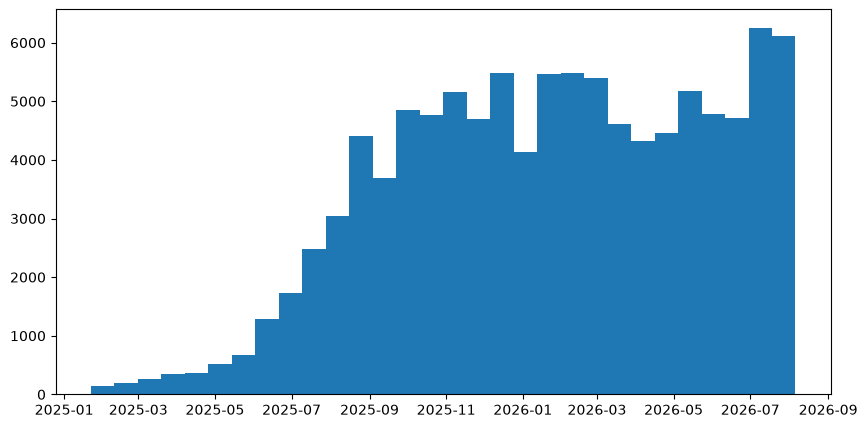

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(
    pplVDfrom5["stay_book_out_date_time"].dropna(),
    bins=30
)
# ok, the ruling does not seem to have had an obvious impact. 
# the VD increase from inaug to august is super visibly exponential but that was known already

In [41]:
releasedfrom5 = lastin5[lastin5["stay_release_reason_simple"] == 'Released']

releasedfrom5 = releasedfrom5.sort_values("book_in_date_time")
pplreleasedfrom5 = releasedfrom5.drop_duplicates(subset=["unique_identifier"], keep="last")
pplreleasedfrom5["stay_book_out_date_time"].describe()

count                               15745
mean     2025-11-26 15:13:35.813274+00:00
min             2025-01-20 08:10:00+00:00
25%             2025-07-01 17:00:00+00:00
50%             2025-12-20 11:54:00+00:00
75%             2026-04-11 08:11:00+00:00
max             2026-08-05 20:35:00+00:00
Name: stay_book_out_date_time, dtype: object

(array([104., 116., 248., 518., 568., 603., 662., 613., 775., 687., 391.,
        328., 337., 472., 342., 337., 379., 489., 394., 854., 796., 602.,
        695., 577., 626., 697., 554., 703., 695., 583.]),
 array([20108.34027778, 20127.09085648, 20145.84143519, 20164.59201389,
        20183.34259259, 20202.0931713 , 20220.84375   , 20239.5943287 ,
        20258.34490741, 20277.09548611, 20295.84606481, 20314.59664352,
        20333.34722222, 20352.09780093, 20370.84837963, 20389.59895833,
        20408.34953704, 20427.10011574, 20445.85069444, 20464.60127315,
        20483.35185185, 20502.10243056, 20520.85300926, 20539.60358796,
        20558.35416667, 20577.10474537, 20595.85532407, 20614.60590278,
        20633.35648148, 20652.10706019, 20670.85763889]),
 <BarContainer object of 30 artists>)

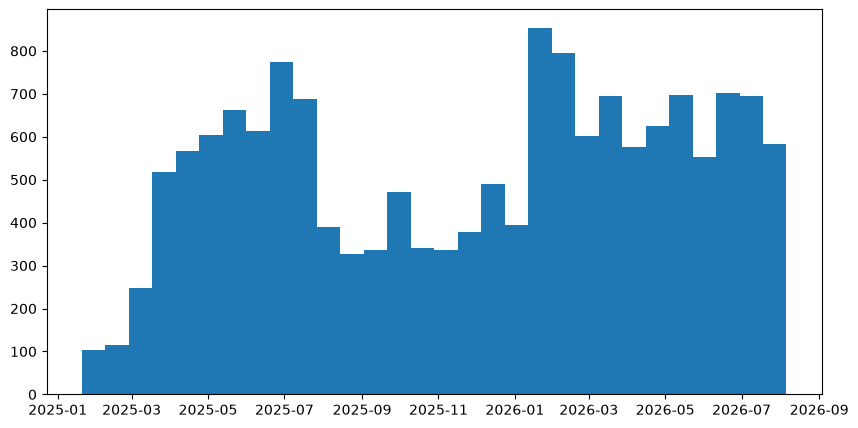

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(
    pplreleasedfrom5["stay_book_out_date_time"].dropna(),
    bins=30
)



In [43]:
deportedfrom5 = lastin5[lastin5["stay_release_reason_simple"] == 'Deported']

deportedfrom5 = deportedfrom5.sort_values("book_in_date_time")
ppldeportedfrom5 = deportedfrom5.drop_duplicates(subset=["unique_identifier"], keep="last")
ppldeportedfrom5["stay_book_out_date_time"].describe()

count                              324439
mean     2025-12-08 16:41:34.082893+00:00
min             2025-01-20 12:32:00+00:00
25%             2025-08-19 19:14:00+00:00
50%             2025-12-09 06:51:00+00:00
75%             2026-04-09 11:32:00+00:00
max             2026-08-05 17:36:00+00:00
Name: stay_book_out_date_time, dtype: object

(array([ 1250.,  2653.,  4200.,  5780.,  5234.,  7864.,  8928.,  9751.,
         9998., 10853., 10898., 13890., 12909., 13778., 13437., 15398.,
        12887., 14693., 10431., 13082., 13433., 12915., 11911., 10492.,
        10625., 13288., 11083., 12597., 15147., 15034.]),
 array([20108.52222222, 20127.26259259, 20146.00296296, 20164.74333333,
        20183.4837037 , 20202.22407407, 20220.96444444, 20239.70481481,
        20258.44518519, 20277.18555556, 20295.92592593, 20314.6662963 ,
        20333.40666667, 20352.14703704, 20370.88740741, 20389.62777778,
        20408.36814815, 20427.10851852, 20445.84888889, 20464.58925926,
        20483.32962963, 20502.07      , 20520.81037037, 20539.55074074,
        20558.29111111, 20577.03148148, 20595.77185185, 20614.51222222,
        20633.25259259, 20651.99296296, 20670.73333333]),
 <BarContainer object of 30 artists>)

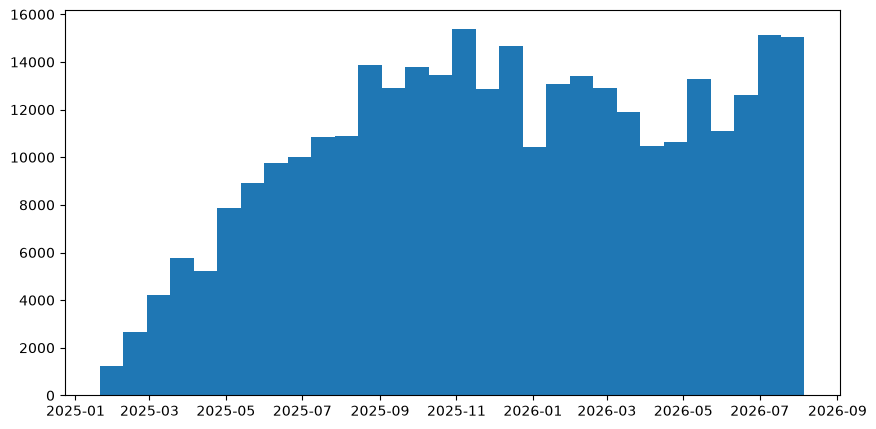

In [53]:
plt.figure(figsize=(10, 5))
plt.hist(
    ppldeportedfrom5["stay_book_out_date_time"].dropna(),
    bins=30
)
